# PakWheels EDA charts

This notebook is an **optional, read-only visual companion** to the cleaning pipeline. It reads `data/processed/pakwheels_clean.csv` and displays charts; it does not change the source data, pipeline code, or cleaned CSV.

If the processed CSV is missing, first run `python -m src.run_pipeline` from the project folder.

The plotted price is the cleaned target in PKR millions. Outliers in price, mileage and selected features have already been capped by the pipeline. These charts are for exploration, not causal conclusions.

In [ ]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project folder whether the notebook kernel starts in the root or notebooks/.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed" / "pakwheels_clean.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/processed/pakwheels_clean.csv. Open the project folder and run the pipeline first."
    )

clean_path = PROJECT_ROOT / "data" / "processed" / "pakwheels_clean.csv"
df = pd.read_csv(clean_path)

# The model table uses one-hot fuel columns. Recover their omitted reference category
# from the raw CSV so the chart shows readable fuel names too.
raw_path = PROJECT_ROOT / "data" / "raw" / "pakwheeldataset.csv"
raw_fuel = pd.read_csv(raw_path, usecols=["Fuel Type"], dtype=str, keep_default_na=False)["Fuel Type"].str.strip()
source_fuels = {v for v in raw_fuel.unique() if v and v.upper() != "N/A"} | {"Electric"}
fuel_dummy_cols = [c for c in df.columns if c.startswith("fuel_type_")]
dummy_fuels = {c.removeprefix("fuel_type_") for c in fuel_dummy_cols}
reference_fuels = sorted(source_fuels - dummy_fuels)
if len(reference_fuels) != 1:
    raise ValueError(f"Expected one reference fuel category, found: {reference_fuels}")
df["fuel_type"] = reference_fuels[0]
for column in fuel_dummy_cols:
    fuel_name = column.removeprefix("fuel_type_")
    df.loc[df[column].eq(1), "fuel_type"] = fuel_name

# Consistent readable styling for the charts.
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.labelsize": 10})
price_m = df["price_pkr"] / 1_000_000
print(f"Loaded {len(df):,} cleaned listings with {df.shape[1]} columns from: {clean_path.relative_to(PROJECT_ROOT)}")
display(df[["car_name", "price_pkr", "mileage_km", "engine_cc", "is_automatic", "fuel_type"]].head())

Loaded 1,001 cleaned listings with 41 columns from: data/processed/pakwheels_clean.csv


,car_name,price_pkr,mileage_km,engine_cc,is_automatic,fuel_type
0,Toyota Land Cruiser Cygnus 2005,1.230000e+07,78931.0,2800.0,1,Petrol
1,Hyundai Elantra GLS 2022,6.600000e+06,9028.0,1300.0,1,Petrol
2,Toyota Prado TX 2.7 2018,2.398569e+07,22455.0,2700.0,1,Petrol
3,Toyota Fortuner 2.8 Sigma 4 2021,1.850000e+07,15193.0,2800.0,1,Diesel
4,Toyota Prado TX Limited 2.7 2007,8.100000e+06,129755.0,2700.0,1,Petrol


## 1. Listing-price distribution

The median line provides a reference point; the target is shown in PKR millions.

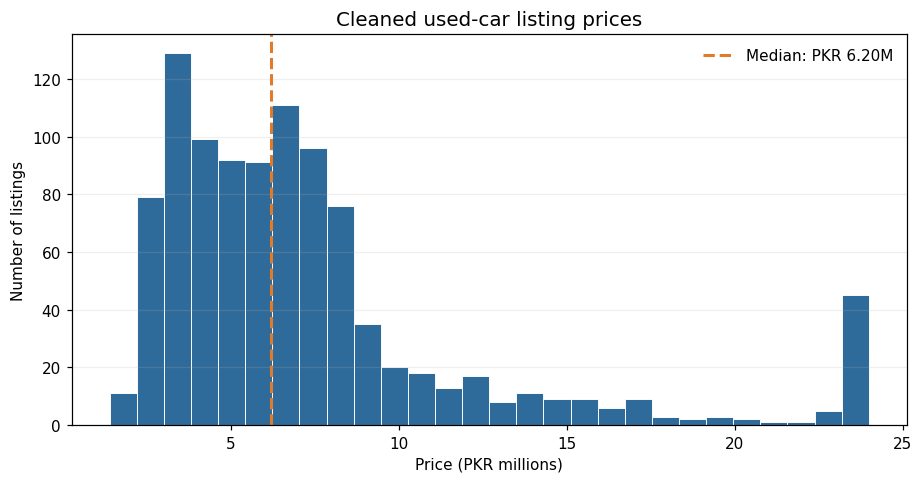

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.hist(price_m, bins=28, color="#2f6b9a", edgecolor="white", linewidth=0.6)
median_price = price_m.median()
ax.axvline(median_price, color="#e07a2d", linestyle="--", linewidth=2, label=f"Median: PKR {median_price:.2f}M")
ax.set(title="Cleaned used-car listing prices", xlabel="Price (PKR millions)", ylabel="Number of listings")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 2. Mileage and price

Mileage uses a logarithmic x-axis so both low- and high-mileage ads are visible. Points are grouped by the automatic/manual indicator.

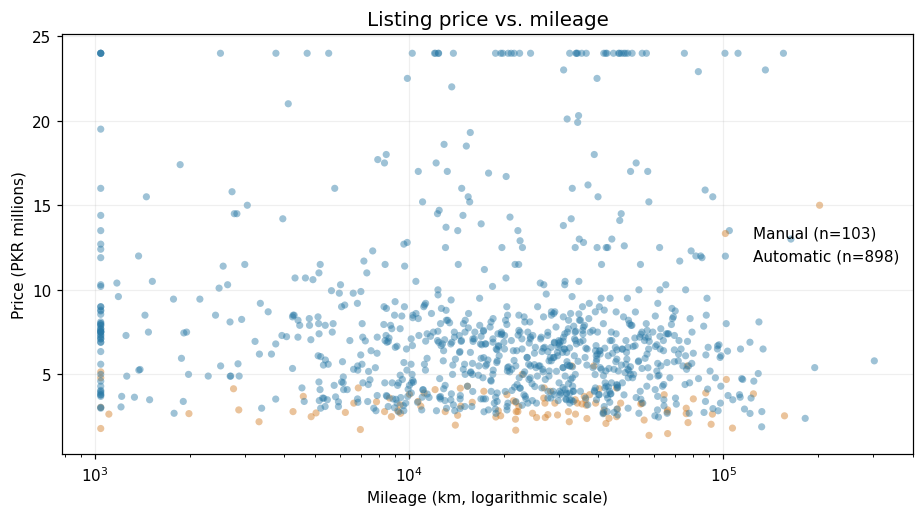

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = {0: "#d17a22", 1: "#2878a5"}
labels = {0: "Manual", 1: "Automatic"}
for value in (0, 1):
    part = df[df["is_automatic"].eq(value)]
    ax.scatter(
        part["mileage_km"], part["price_pkr"] / 1_000_000,
        s=22, alpha=0.45, color=colors[value], edgecolors="none",
        label=f"{labels[value]} (n={len(part):,})",
    )
ax.set_xscale("log")
ax.set(title="Listing price vs. mileage", xlabel="Mileage (km, logarithmic scale)", ylabel="Price (PKR millions)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 3. Price by fuel type

Box plots compare medians and spreads. Outlier markers are hidden to make the middle 50% easier to compare; the underlying rows are unchanged.

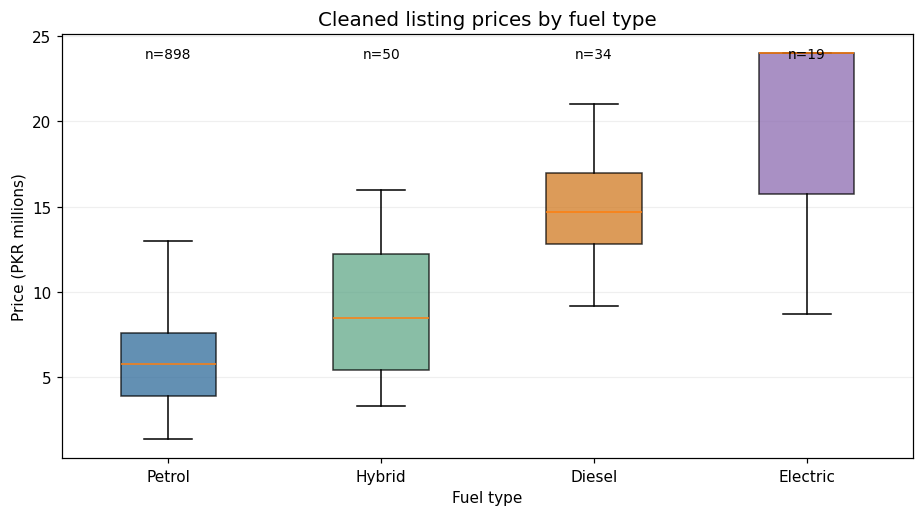

In [4]:
fuel_order = [name for name in ("Petrol", "Hybrid", "Diesel", "Electric") if name in set(df["fuel_type"])]
fuel_values = [df.loc[df["fuel_type"].eq(name), "price_pkr"] / 1_000_000 for name in fuel_order]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
boxes = ax.boxplot(fuel_values, showfliers=False, patch_artist=True)
for patch, color in zip(boxes["boxes"], ["#2f6b9a", "#61a889", "#d17a22", "#8c6bb1"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax.set_xticks(range(1, len(fuel_order) + 1), fuel_order)
ax.set(title="Cleaned listing prices by fuel type", xlabel="Fuel type", ylabel="Price (PKR millions)")
ax.grid(axis="y", alpha=0.2)
for xpos, name in enumerate(fuel_order, start=1):
    count = int(df["fuel_type"].eq(name).sum())
    ax.text(xpos, ax.get_ylim()[1] * 0.97, f"n={count}", ha="center", va="top", fontsize=9)
fig.tight_layout()
plt.show()

## 4. Feature relationships with price

Spearman correlations summarize rank-based association with price across all listings. They are descriptive—not evidence that a feature causes a price change.

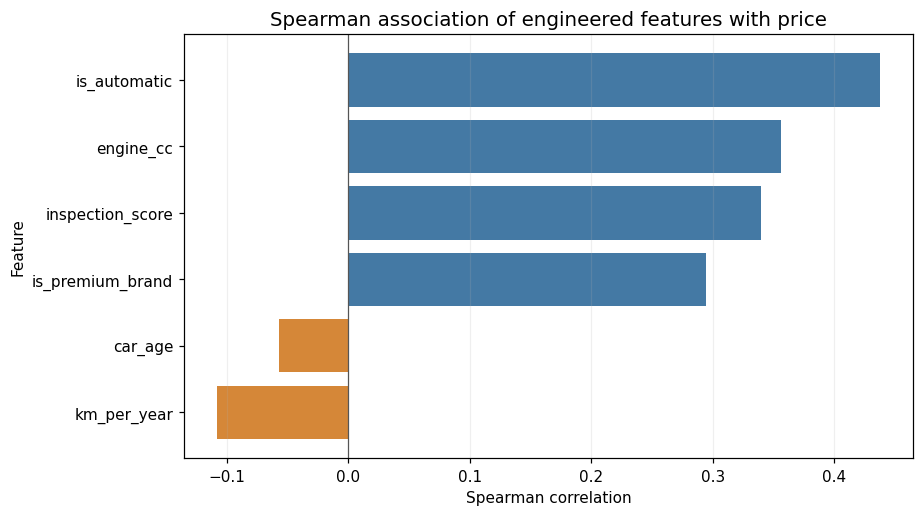

,Spearman correlation with price
is_automatic,0.437487
engine_cc,0.356187
inspection_score,0.339533
is_premium_brand,0.294494
car_age,-0.057124
km_per_year,-0.108020


In [5]:
feature_cols = [
    "car_age", "km_per_year", "inspection_score",
    "engine_cc", "is_premium_brand", "is_automatic",
]
correlations = df[feature_cols + ["price_pkr"]].corr(method="spearman")["price_pkr"].drop("price_pkr").sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bar_colors = ["#d17a22" if value < 0 else "#2f6b9a" for value in correlations.values]
ax.barh(correlations.index, correlations.values, color=bar_colors, alpha=0.9)
ax.axvline(0, color="#555555", linewidth=0.8)
ax.set(title="Spearman association of engineered features with price", xlabel="Spearman correlation", ylabel="Feature")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()
correlations.to_frame("Spearman correlation with price").sort_values("Spearman correlation with price", ascending=False)

## Notes

- The charts read the saved model-ready CSV and do not modify it.
- `listing_id` and `car_name` are identifiers, not model inputs.
- Re-run the pipeline first if you change its settings or regenerate the cleaned CSV, then re-run these notebook cells to refresh the charts.